# Análise Exploratória do Comércio de Chá Verde

## 1. Contextualização

O comércio internacional de chá verde envolve diferentes apresentações comerciais, mercados de origem e destino e características de negociação.

Este projeto utiliza dados públicos do Comex Stat para investigar o comportamento das importações e exportações brasileiras de chá verde entre 2010 e 2024.

A análise considera os códigos NCM 09021000 e 09022000, permitindo comparar categorias de apresentação do produto, identificar parceiros comerciais e acompanhar a evolução dos valores e volumes negociados.

In [1]:
# Importando as bibliotecas
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Carregando o dataset
exp = pd.read_csv('../dados/exportacao_2010_2024.csv', sep=';')
imp = pd.read_csv('../dados/importacao_2010_2024.csv', sep=';')

In [3]:
# Dataset Exportação
exp.head()

,Ano,Mês,UF do Produto,Países,Código NCM,Descrição NCM,Valor US$ FOB,Quilograma Líquido
0,2024,12. Dezembro,\rAlagoas,\rHong Kong,9021000,\rChá verde (não fermentado) em embalagens ime...,12,0
1,2024,12. Dezembro,\rAlagoas,\rLibéria,9021000,\rChá verde (não fermentado) em embalagens ime...,69,6
2,2024,12. Dezembro,\rAlagoas,\rLuxemburgo,9021000,\rChá verde (não fermentado) em embalagens ime...,15,1
3,2024,12. Dezembro,\rAlagoas,"\rMarshall, Ilhas",9021000,\rChá verde (não fermentado) em embalagens ime...,0,0
4,2024,12. Dezembro,\rAmazonas,\rLibéria,9021000,\rChá verde (não fermentado) em embalagens ime...,31,0


In [4]:
# Dataset Importação
imp.head()

,Ano,Mês,UF do Produto,Países,Código NCM,Descrição NCM,Valor US$ FOB,US$ Frete,US$ Seguro,Valor US$ CIF,Quilograma Líquido
0,2024,12. Dezembro,\rAlagoas,\rTaiwan (Formosa),9022000,\rChá verde (não fermentado) apresentado de qu...,376,35,0,411,120
1,2024,12. Dezembro,\rMinas Gerais,\rAlemanha,9022000,\rChá verde (não fermentado) apresentado de qu...,16759,1473,21,18253,2025
2,2024,12. Dezembro,\rParaná,\rAlemanha,9022000,\rChá verde (não fermentado) apresentado de qu...,905,1468,1,2374,250
3,2024,12. Dezembro,\rPernambuco,\rEspanha,9021000,\rChá verde (não fermentado) em embalagens ime...,981,12,3,996,43
4,2024,12. Dezembro,\rRio de Janeiro,\rFrança,9021000,\rChá verde (não fermentado) em embalagens ime...,958,10,0,968,22


In [5]:
# Tirando os espaços em branco dos dados da Exportação
exp['Descrição NCM'] = exp['Descrição NCM'].str.strip()
exp['UF do Produto'] = exp['UF do Produto'].str.strip()
exp['Países'] = exp['Países'].str.strip()


# Tirando os espaços em branco dos dados da Importação
imp['Descrição NCM'] = imp['Descrição NCM'].str.strip()
imp['UF do Produto'] = imp['UF do Produto'].str.strip()
imp['Países'] = imp['Países'].str.strip()

In [6]:
# Informações gerais dos datasets
print("Informações do dataset de Exportação:")
exp.info()
print("\nInformações do dataset de Importação:")    
imp.info()

Informações do dataset de Exportação:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7756 entries, 0 to 7755
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Ano                 7756 non-null   int64 
 1   Mês                 7756 non-null   object
 2   UF do Produto       7756 non-null   object
 3   Países              7756 non-null   object
 4   Código NCM          7756 non-null   int64 
 5   Descrição NCM       7756 non-null   object
 6   Valor US$ FOB       7756 non-null   int64 
 7   Quilograma Líquido  7756 non-null   int64 
dtypes: int64(4), object(4)
memory usage: 484.9+ KB

Informações do dataset de Importação:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2494 entries, 0 to 2493
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Ano                 2494 non-null   int64 
 1   Mês                 2494 non-

## 2. Estatística Descritiva

In [7]:
# Estatísticas descritivas
print("Exportação")
exp[['Quilograma Líquido', 'Valor US$ FOB']].describe()


Exportação


,Quilograma Líquido,Valor US$ FOB
count,7756.000000,7756.000000
mean,588.790614,4631.352888
std,4085.431127,32605.899335
min,0.000000,0.000000
25%,0.000000,17.000000
50%,2.000000,50.000000
75%,14.000000,178.000000
max,83774.000000,675878.000000


In [8]:
# Estatísticas descritivas
print("Importação")
imp[['Quilograma Líquido', 'Valor US$ FOB', 'US$ Frete', 'US$ Seguro', 'Valor US$ CIF']].describe()

Importação


,Quilograma Líquido,Valor US$ FOB,US$ Frete,US$ Seguro,Valor US$ CIF
count,2494.000000,2494.000000,2494.000000,2494.000000,2494.000000
mean,2988.684443,10291.558540,677.693264,13.943063,10983.194868
std,6597.596986,16736.966886,1395.334459,45.078814,17608.401891
min,0.000000,1.000000,0.000000,0.000000,3.000000
25%,44.250000,1140.000000,27.000000,0.000000,1266.750000
50%,300.000000,4587.500000,180.000000,0.000000,4935.500000
75%,2250.000000,12329.250000,701.500000,9.000000,13198.500000
max,75850.000000,249286.000000,25666.000000,757.000000,254371.000000


## 3. Análise Exploratória

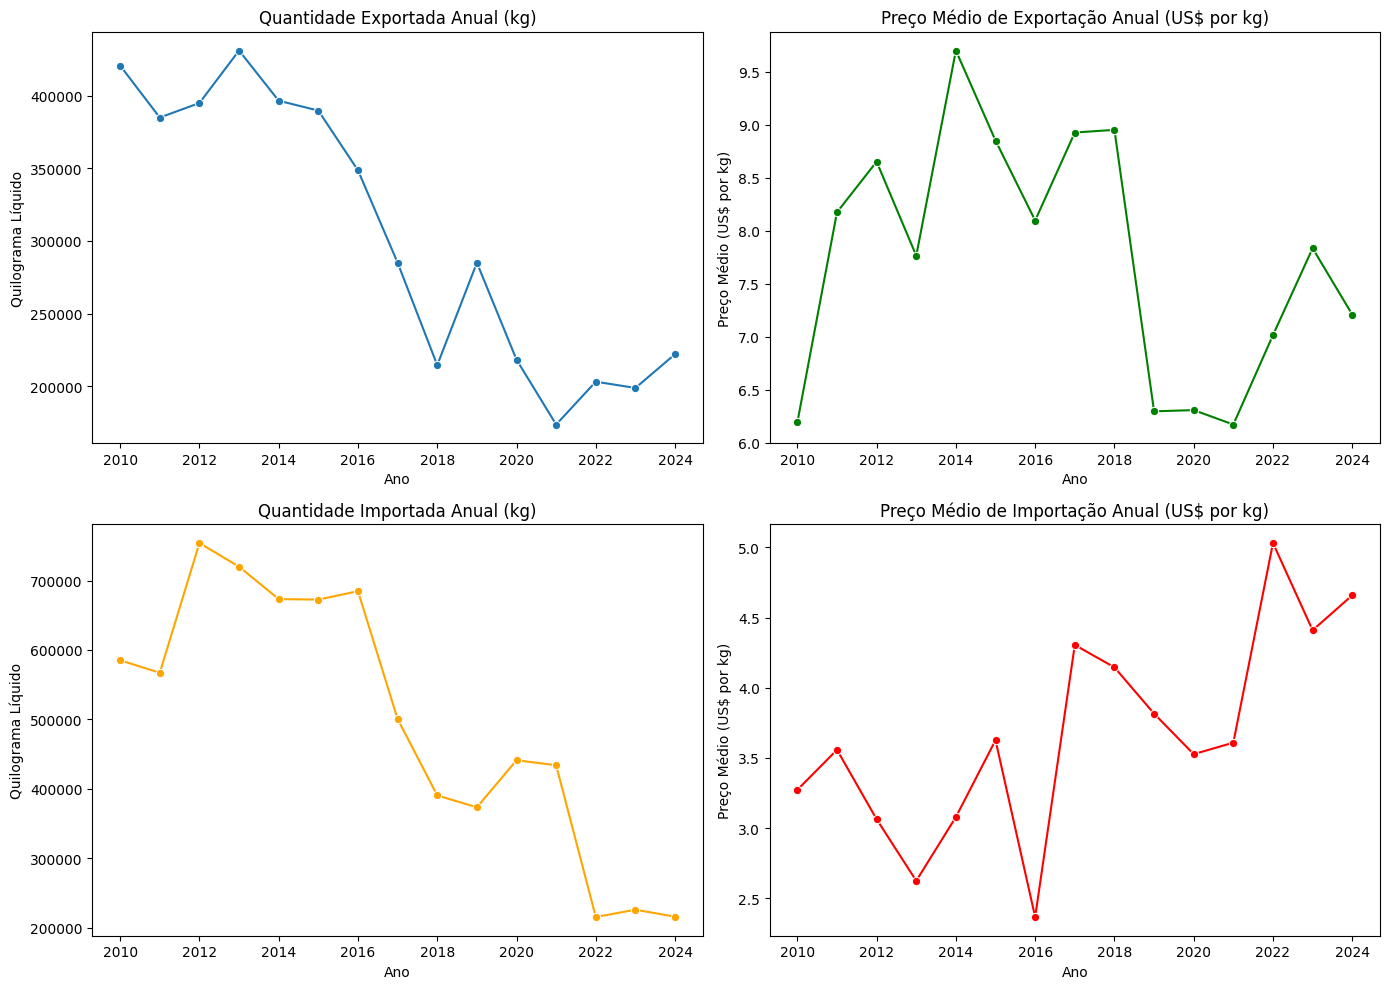

In [9]:
# Gráficos de quantidade e preço da exportação e importação por ano
exp_anual = exp.groupby('Ano').agg({'Quilograma Líquido': 'sum', 'Valor US$ FOB': 'sum'}).reset_index()
exp_anual['Preço Médio (US$ por kg)'] = exp_anual['Valor US$ FOB'] / exp_anual['Quilograma Líquido']
imp_anual = imp.groupby('Ano').agg({'Quilograma Líquido': 'sum', 'Valor US$ FOB': 'sum'}).reset_index()
imp_anual['Preço Médio (US$ por kg)'] = imp_anual['Valor US$ FOB'] / imp_anual['Quilograma Líquido']

# Configurando os gráficos
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# Gráfico 1: Quantidade Exportada Anual
sns.lineplot(data=exp_anual, x='Ano', y='Quilograma Líquido', marker='o', ax=axs[0, 0])
axs[0, 0].set_title('Quantidade Exportada Anual (kg)')  
axs[0, 0].set_xlabel('Ano')
axs[0, 0].set_ylabel('Quilograma Líquido')

# Gráfico 2: Preço Médio de Exportação Anual
sns.lineplot(data=exp_anual, x='Ano', y='Preço Médio (US$ por kg)', marker='o', color='green', ax=axs[0, 1])
axs[0, 1].set_title('Preço Médio de Exportação Anual (US$ por kg)')
axs[0, 1].set_xlabel('Ano')
axs[0, 1].set_ylabel('Preço Médio (US$ por kg)')

# Gráfico 3: Quantidade Importada Anual
sns.lineplot(data=imp_anual, x='Ano', y='Quilograma Líquido', marker='o', color='orange', ax=axs[1, 0])
axs[1, 0].set_title('Quantidade Importada Anual (kg)')
axs[1, 0].set_xlabel('Ano')
axs[1, 0].set_ylabel('Quilograma Líquido')

# Gráfico 4: Preço Médio de Importação Anual
sns.lineplot(data=imp_anual, x='Ano', y='Preço Médio (US$ por kg)', marker='o', color='red', ax=axs[1, 1])
axs[1, 1].set_title('Preço Médio de Importação Anual (US$ por kg)')
axs[1, 1].set_xlabel('Ano') 
axs[1, 1].set_ylabel('Preço Médio (US$ por kg)')
plt.tight_layout()
plt.show()

In [10]:
# Exportação por País
top_exp_paises = exp.groupby('Países').agg({'Quilograma Líquido': 'sum', 'Valor US$ FOB': 'sum'}).reset_index()
top_exp_paises = top_exp_paises.sort_values(by='Quilograma Líquido', ascending=False).head(10)
top_exp_paises['Preço Médio (US$ por kg)'] = round(top_exp_paises['Valor US$ FOB'] / top_exp_paises['Quilograma Líquido'],2)
top_exp_paises

,Países,Quilograma Líquido,Valor US$ FOB,Preço Médio (US$ por kg)
41,Estados Unidos,3766412,29488892,7.83
59,Japão,489181,3644000,7.45
81,Paraguai,37291,131668,3.53
44,França,29704,77320,2.60
0,Alemanha,24244,82870,3.42
104,Venezuela,23435,579268,24.72
70,"Marshall, Ilhas",23073,91151,3.95
109,Índia,20350,156796,7.70
79,Panamá,17447,80294,4.60
1,Angola,16390,315841,19.27


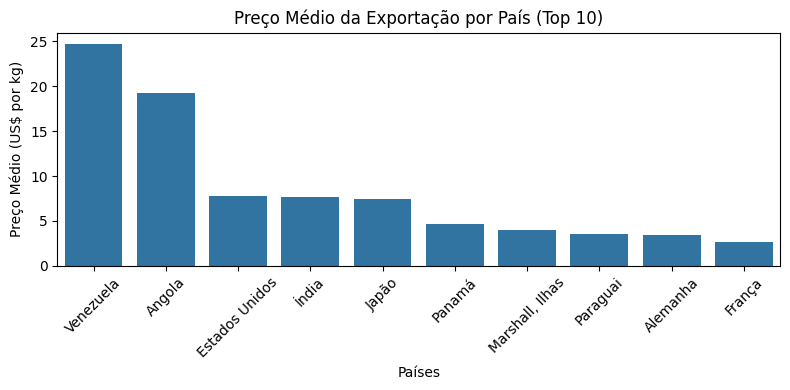

In [11]:
# preço médio da exportação por país
plt.figure(figsize=(8, 4))
sns.barplot(data=top_exp_paises.sort_values(by='Preço Médio (US$ por kg)', ascending=False), x='Países', y='Preço Médio (US$ por kg)')
plt.title('Preço Médio da Exportação por País (Top 10)')
plt.xlabel('Países')
plt.ylabel('Preço Médio (US$ por kg)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
# importação por País
top_imp_paises = imp.groupby('Países').agg({'Quilograma Líquido': 'sum', 'Valor US$ FOB': 'sum'}).reset_index()
top_imp_paises = top_imp_paises.sort_values(by='Quilograma Líquido', ascending=False).head(10)
top_imp_paises['Preço Médio (US$ por kg)'] = round(top_imp_paises['Valor US$ FOB'] / top_imp_paises['Quilograma Líquido'],2)
top_imp_paises

,Países,Quilograma Líquido,Valor US$ FOB,Preço Médio (US$ por kg)
6,China,2472681,7009092,2.83
1,Argentina,1941171,3639353,1.87
40,Índia,1345314,1037791,0.77
0,Alemanha,892695,3630831,4.07
19,Japão,222405,2174092,9.78
24,Paraguai,161890,1560923,9.64
5,Chile,50966,814892,15.99
32,Sri Lanka,49243,443318,9.00
38,Vietnã,47960,105678,2.20
36,Taiwan (Formosa),45021,216469,4.81


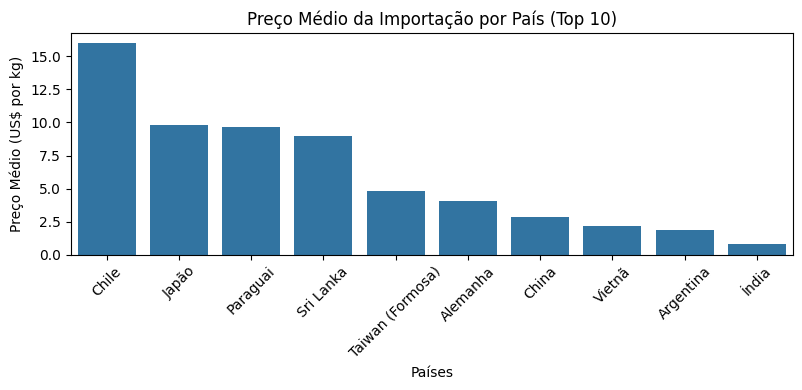

In [13]:
# Preço médio da importação por país
plt.figure(figsize=(8, 4))
sns.barplot(data=top_imp_paises.sort_values(by='Preço Médio (US$ por kg)', ascending=False), x='Países', y='Preço Médio (US$ por kg)')
plt.title('Preço Médio da Importação por País (Top 10)')
plt.xlabel('Países')
plt.ylabel('Preço Médio (US$ por kg)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
